# Effect of Different n Values on Stability and Eigenvalues

This notebook explores how different Hill coefficients (n values) for each neuron type (r, g, b, y) affect:
1. Network stability (eigenvalues of the stability matrix A)
2. Hessian eigenvalues and eigenvectors
3. Participation ratio
4. Other eigenvalue-related properties


In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from itertools import product

# Set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Plotting style
plt.rcParams.update({'font.size': 12, 'figure.figsize': (10, 6)})

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal


## Modified Functions with Different n Values

We modify the Naka-Rushton function and circuit functions to accept different n values for each neuron type: n_r, n_g, n_b, n_y.


In [ ]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r=4, n_b=4, n_g=4):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)
    
    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)
    
    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)
    
    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r=4, n_b=4, n_g=4):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)
    
    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)
    
    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    
    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)
    
    return r, g, b, y


## Dynamics Function and Stability Analysis

We define the dynamics function F(s) and compute stability with different n values.


In [4]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r=4, n_b=4, n_g=4, n_y=4):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)
    
    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=4, n_b=4, n_g=4, n_y=4):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [5]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

# Use a subset of samples for faster analysis
n_samples_to_analyze = 10
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28

Using 10 samples for analysis


## Different n Value Combinations

We'll test different combinations of n values for each neuron type and analyze their effects on stability and eigenvalues.


In [ ]:
# Define n values to test
n_values_to_test = [4, 8, 12, 16]

# Test different combinations - all values must come from n_values_to_test
n_combinations = [
    # Baseline: all same (lowest value)
    {'n_r': 4, 'n_b': 4, 'n_g': 4, 'n_y': 4, 'name': 'Baseline (all n=4)'},
    # Different n for each type (using all values)
    {'n_r': 4, 'n_b': 8, 'n_g': 12, 'n_y': 16, 'name': 'r=4, b=8, g=12, y=16'},
    {'n_r': 16, 'n_b': 12, 'n_g': 8, 'n_y': 4, 'name': 'r=16, b=12, g=8, y=4'},
    # All same but different values
    {'n_r': 8, 'n_b': 8, 'n_g': 8, 'n_y': 8, 'name': 'All n=8'},
    {'n_r': 12, 'n_b': 12, 'n_g': 12, 'n_y': 12, 'name': 'All n=12'},
    {'n_r': 16, 'n_b': 16, 'n_g': 16, 'n_y': 16, 'name': 'All n=16'},
    # Mixed: low for some, high for others
    {'n_r': 4, 'n_b': 16, 'n_g': 4, 'n_y': 16, 'name': 'r=4, b=16, g=4, y=16'},
    {'n_r': 16, 'n_b': 4, 'n_g': 16, 'n_y': 4, 'name': 'r=16, b=4, g=16, y=4'},
    # Mixed: medium values
    {'n_r': 8, 'n_b': 12, 'n_g': 8, 'n_y': 12, 'name': 'r=8, b=12, g=8, y=12'},
]

print(f"Testing {len(n_combinations)} different n value combinations")
for i, combo in enumerate(n_combinations):
    print(f"{i+1}. {combo['name']}: n_r={combo['n_r']}, n_b={combo['n_b']}, n_g={combo['n_g']}, n_y={combo['n_y']}")


In [14]:
# Define n values to test
n_values_to_test = [2, 4, 6, 8]

# Test different combinations - all values must come from n_values_to_test
n_combinations = [
    # Baseline: all same (lowest value)
    {'n_r': 4, 'n_b': 4, 'n_g': 4, 'n_y': 4, 'name': 'Baseline (all n=4)'},
    # Different n for each type (using all values)
    {'n_r': 2, 'n_b': 4, 'n_g': 6, 'n_y': 8, 'name': 'r=2, b=4, g=6, y=8'},
    {'n_r': 8, 'n_b': 6, 'n_g': 4, 'n_y': 2, 'name': 'r=8, b=6, g=4, y=2'},
    # All same but different values
    {'n_r': 4, 'n_b': 4, 'n_g': 4, 'n_y': 4, 'name': 'All n=4'},
    {'n_r': 6, 'n_b': 6, 'n_g': 6, 'n_y': 6, 'name': 'All n=6'},
    {'n_r': 8, 'n_b': 8, 'n_g': 8, 'n_y': 8, 'name': 'All n=8'},
    # Mixed: low for some, high for others
    {'n_r': 2, 'n_b': 8, 'n_g': 2, 'n_y': 8, 'name': 'r=2, b=8, g=2, y=8'},
    {'n_r': 8, 'n_b': 2, 'n_g': 8, 'n_y': 2, 'name': 'r=8, b=2, g=8, y=2'},
    # Mixed: medium values
    {'n_r': 4, 'n_b': 6, 'n_g': 4, 'n_y': 6, 'name': 'r=4, b=6, g=4, y=6'},
]

print(f"Testing {len(n_combinations)} different n value combinations")
for i, combo in enumerate(n_combinations):
    print(f"{i+1}. {combo['name']}: n_r={combo['n_r']}, n_b={combo['n_b']}, n_g={combo['n_g']}, n_y={combo['n_y']}")


Testing 9 different n value combinations
1. Baseline (all n=4): n_r=4, n_b=4, n_g=4, n_y=4
2. r=2, b=4, g=6, y=8: n_r=2, n_b=4, n_g=6, n_y=8
3. r=8, b=6, g=4, y=2: n_r=8, n_b=6, n_g=4, n_y=2
4. All n=4: n_r=4, n_b=4, n_g=4, n_y=4
5. All n=6: n_r=6, n_b=6, n_g=6, n_y=6
6. All n=8: n_r=8, n_b=8, n_g=8, n_y=8
7. r=2, b=8, g=2, y=8: n_r=2, n_b=8, n_g=2, n_y=8
8. r=8, b=2, g=8, y=2: n_r=8, n_b=2, n_g=8, n_y=2
9. r=4, b=6, g=4, y=6: n_r=4, n_b=6, n_g=4, n_y=6


## Stability Analysis for Different n Values

For each combination of n values, we compute:
1. Stability (whether all eigenvalues have negative real parts)
2. Real parts of eigenvalues
3. Imaginary parts of eigenvalues
4. Maximum real part (determines stability margin)


In [15]:
# Analyze stability for each n combination
stability_results_all = {}

for combo in n_combinations:
    n_r = combo['n_r']
    n_b = combo['n_b']
    n_g = combo['n_g']
    n_y = combo['n_y']
    name = combo['name']
    
    print(f"\n{'='*70}")
    print(f"Analyzing: {name}")
    print(f"{'='*70}")
    
    stability_results = []
    max_real_parts = []
    min_real_parts = []
    all_eigenvalues = []
    
    for i in range(n_samples_to_analyze):
        theta_star = theta_subset[i, :]
        
        # Get fixed point outputs with new n values
        try:
            r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)
            
            # Construct state vector s* = [r, g, y]
            s_star = jnp.concatenate([r_star, g_star, y_star])
            
            # Verify it's a fixed point
            s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
            s_error = jnp.linalg.norm(s_prime - s_star)
            
            if s_error > 1e-3:
                print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")
            
            # Compute stability
            result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
            stability_results.append(result)
            
            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            all_eigenvalues.append(result['eigenvalues'])
            
        except Exception as e:
            print(f"  Sample {i+1}: Error - {e}")
            continue
    
    # Store results
    stability_results_all[name] = {
        'results': stability_results,
        'max_real_parts': np.array(max_real_parts),
        'min_real_parts': np.array(min_real_parts),
        'all_eigenvalues': all_eigenvalues,
        'n_r': n_r,
        'n_b': n_b,
        'n_g': n_g,
        'n_y': n_y,
        'stable_count': sum(1 for r in stability_results if r['is_stable']),
        'total_count': len(stability_results)
    }
    
    stable_pct = 100 * stability_results_all[name]['stable_count'] / stability_results_all[name]['total_count']
    print(f"\nStability: {stability_results_all[name]['stable_count']}/{stability_results_all[name]['total_count']} stable ({stable_pct:.1f}%)")
    print(f"Max real part range: [{np.min(max_real_parts):.4f}, {np.max(max_real_parts):.4f}]")
    print(f"Min real part range: [{np.min(min_real_parts):.4f}, {np.max(min_real_parts):.4f}]")



Analyzing: Baseline (all n=4)

Stability: 10/10 stable (100.0%)
Max real part range: [-0.8968, -0.6692]
Min real part range: [-1.3308, -1.1032]

Analyzing: r=2, b=4, g=6, y=8

Stability: 10/10 stable (100.0%)
Max real part range: [-0.9106, -0.7135]
Min real part range: [-1.2865, -1.0894]

Analyzing: r=8, b=6, g=4, y=2

Stability: 10/10 stable (100.0%)
Max real part range: [-0.8540, -0.5321]
Min real part range: [-1.4679, -1.1460]

Analyzing: All n=4

Stability: 10/10 stable (100.0%)
Max real part range: [-0.8968, -0.6692]
Min real part range: [-1.3308, -1.1032]

Analyzing: All n=6

Stability: 10/10 stable (100.0%)
Max real part range: [-0.8452, -0.5038]
Min real part range: [-1.4962, -1.1548]

Analyzing: All n=8

Stability: 10/10 stable (100.0%)
Max real part range: [-0.7935, -0.3383]
Min real part range: [-1.6617, -1.2065]

Analyzing: r=2, b=8, g=2, y=8

Stability: 10/10 stable (100.0%)
Max real part range: [-0.9484, -0.8346]
Min real part range: [-1.1654, -1.0516]

Analyzing: r=8, b

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


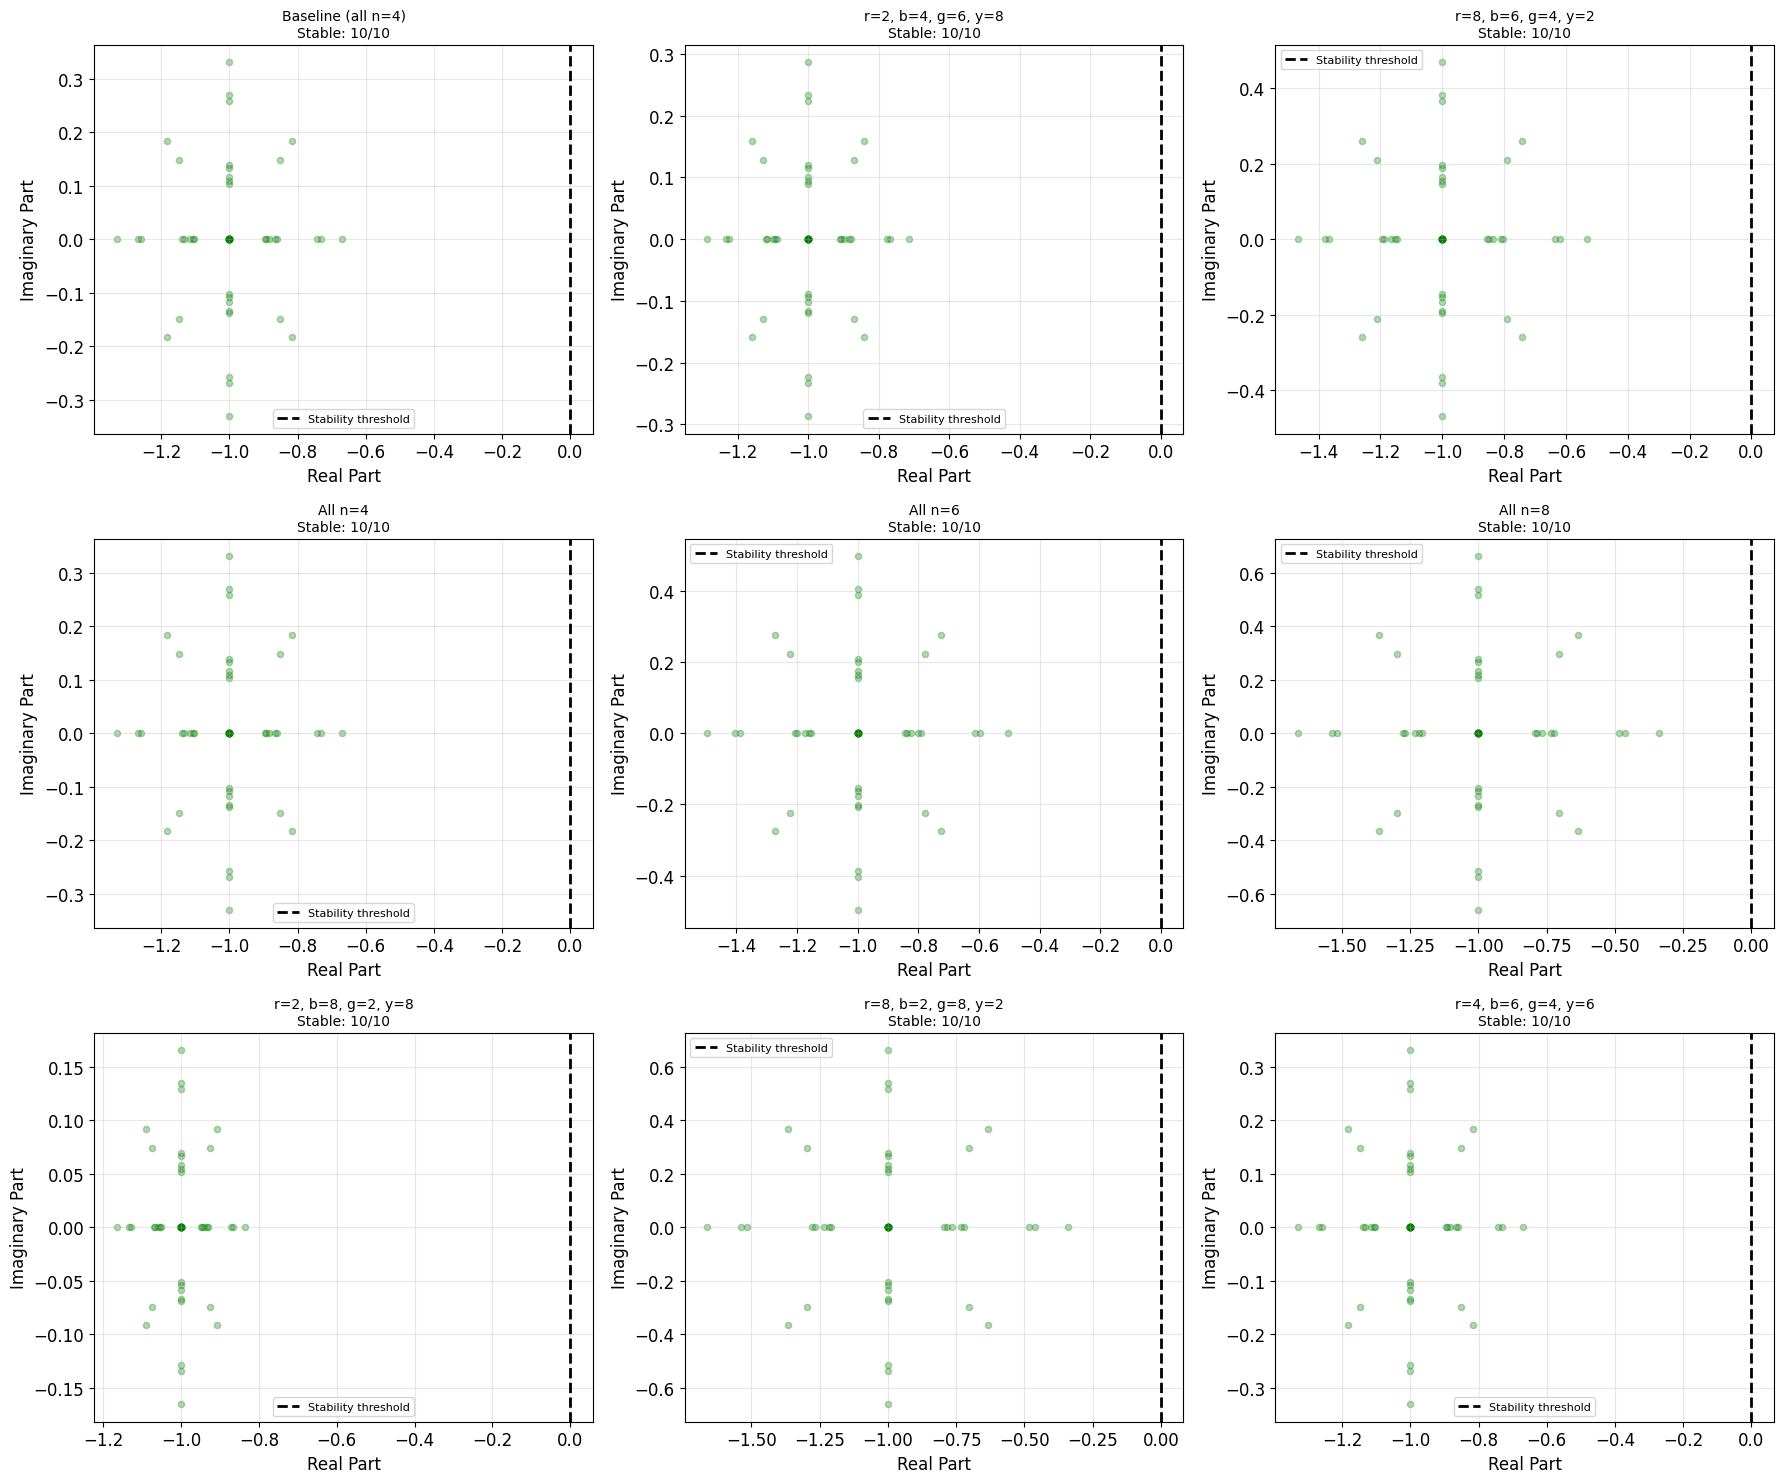

In [18]:
# Plot stability results
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for idx, (name, data) in enumerate(stability_results_all.items()):
    ax = axes[idx]
    
    # Plot eigenvalues for all samples
    for i, result in enumerate(data['results']):
        real_parts = result['real_parts']
        imag_parts = result['imag_parts']
        
        # Color by stability
        color = 'green' if result['is_stable'] else 'red'
        ax.scatter(real_parts, imag_parts, alpha=0.3, s=20, color=color)
    
    ax.axvline(x=0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
    ax.set_xlabel('Real Part', fontsize=12)
    ax.set_ylabel('Imaginary Part', fontsize=12)
    ax.set_title(f"{name}\nStable: {data['stable_count']}/{data['total_count']}", fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('Figures/stability_different_n_values.eps', format='eps', dpi=300)
plt.show()


## Summary Statistics: Maximum Real Parts

Compare the maximum real parts of eigenvalues across different n combinations. More negative values indicate greater stability.


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_52279/1573572976.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(max_real_data, labels=names, patch_artist=True, showmeans=True)
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


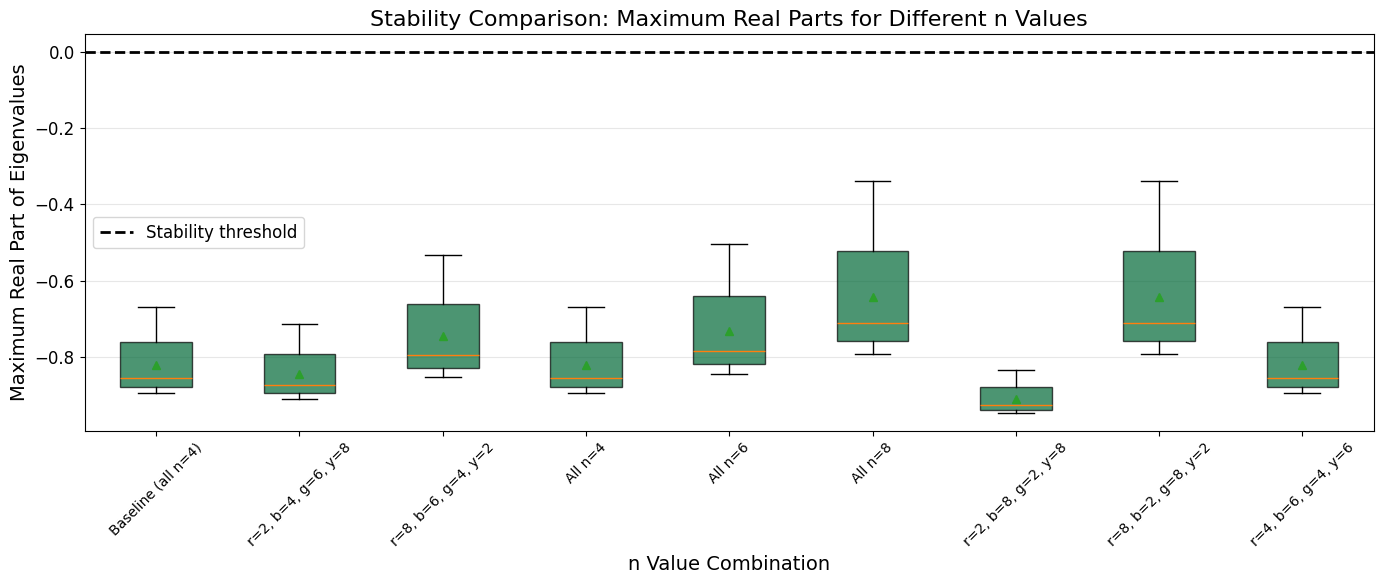


SUMMARY: Maximum Real Parts of Eigenvalues
Combination                              Mean         Std          Min          Max          Stable %  
----------------------------------------------------------------------------------------------------
Baseline (all n=4)                          -0.8211     0.0753    -0.8968    -0.6692    100.0%
r=2, b=4, g=6, y=8                          -0.8450     0.0652    -0.9106    -0.7135    100.0%
r=8, b=6, g=4, y=2                          -0.7470     0.1064    -0.8540    -0.5321    100.0%
All n=4                                     -0.8211     0.0753    -0.8968    -0.6692    100.0%
All n=6                                     -0.7316     0.1129    -0.8452    -0.5038    100.0%
All n=8                                     -0.6421     0.1505    -0.7935    -0.3383    100.0%
r=2, b=8, g=2, y=8                          -0.9105     0.0376    -0.9484    -0.8346    100.0%
r=8, b=2, g=8, y=2                          -0.6421     0.1505    -0.7935    -0.3383  

In [19]:
# Box plot of maximum real parts
fig, ax = plt.subplots(figsize=(14, 6))

names = []
max_real_data = []
colors = []

for name, data in stability_results_all.items():
    names.append(name)
    max_real_data.append(data['max_real_parts'])
    # Color: green if mostly stable, red if mostly unstable
    stable_pct = data['stable_count'] / data['total_count']
    colors.append(plt.cm.RdYlGn(stable_pct))

bp = ax.boxplot(max_real_data, labels=names, patch_artist=True, showmeans=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.axhline(y=0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
ax.set_ylabel('Maximum Real Part of Eigenvalues', fontsize=14)
ax.set_xlabel('n Value Combination', fontsize=14)
ax.set_title('Stability Comparison: Maximum Real Parts for Different n Values', fontsize=16)
ax.tick_params(axis='x', rotation=45, labelsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.legend(fontsize=12)

plt.tight_layout()
plt.savefig('Figures/max_real_parts_different_n.eps', format='eps', dpi=300)
plt.show()

# Print summary table
print("\n" + "="*100)
print("SUMMARY: Maximum Real Parts of Eigenvalues")
print("="*100)
print(f"{'Combination':<40} {'Mean':<12} {'Std':<12} {'Min':<12} {'Max':<12} {'Stable %':<10}")
print("-"*100)
for name, data in stability_results_all.items():
    mean_val = np.mean(data['max_real_parts'])
    std_val = np.std(data['max_real_parts'])
    min_val = np.min(data['max_real_parts'])
    max_val = np.max(data['max_real_parts'])
    stable_pct = 100 * data['stable_count'] / data['total_count']
    print(f"{name:<40} {mean_val:>10.4f} {std_val:>10.4f} {min_val:>10.4f} {max_val:>10.4f} {stable_pct:>8.1f}%")


## Hessian Eigenvalue Analysis

Now we analyze how different n values affect the Hessian eigenvalues, which indicate directions in parameter space where changes preserve output.


In [20]:
# Define function that returns output y as a function of parameters (with different n values)
@jax.jit
def y_output_sum(theta, n_r=4, n_b=4, n_g=4, n_y=4):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)  # sum over all y neurons

# Analyze Hessian for different n values
hessian_results_all = {}

print("Computing Hessian eigenvalues for different n combinations...\n")

for combo in n_combinations[:5]:  # Analyze first 5 combinations for speed
    n_r = combo['n_r']
    n_b = combo['n_b']
    n_g = combo['n_g']
    n_y = combo['n_y']
    name = combo['name']
    
    print(f"Analyzing Hessian for: {name}")
    
    # Create functions with specific n values
    def y_output_wrapper(theta):
        return y_output_sum(theta, n_r, n_b, n_g, n_y)
    
    grad_fn = jax.jit(jax.grad(y_output_wrapper))
    hessian_fn = jax.jit(jax.jacrev(grad_fn))
    
    all_eigenvalues_H = []
    participation_ratios = []
    near_zero_counts = []
    
    for i in range(min(5, n_samples_to_analyze)):  # Use fewer samples for Hessian (computationally expensive)
        theta_star = theta_subset[i, :]
        
        try:
            # Compute Hessian
            H = hessian_fn(theta_star)
            H = jnp.squeeze(H)
            
            # Compute eigenvalues
            eigenvalues_H = jnp.linalg.eigh(H)[0]
            eigenvalues_H_np = np.array(eigenvalues_H)
            all_eigenvalues_H.append(eigenvalues_H_np)
            
            # Participation ratio
            ppr = (jnp.sum(jnp.abs(eigenvalues_H)) ** 2) / jnp.sum(eigenvalues_H ** 2)
            participation_ratios.append(float(ppr))
            
            # Count near-zero eigenvalues
            near_zero_threshold = 1e-6
            n_near_zero = np.sum(np.abs(eigenvalues_H_np) < near_zero_threshold)
            near_zero_counts.append(n_near_zero)
            
        except Exception as e:
            print(f"  Sample {i+1}: Error computing Hessian - {e}")
            continue
    
    hessian_results_all[name] = {
        'all_eigenvalues': all_eigenvalues_H,
        'participation_ratios': np.array(participation_ratios),
        'near_zero_counts': np.array(near_zero_counts),
        'n_r': n_r,
        'n_b': n_b,
        'n_g': n_g,
        'n_y': n_y
    }
    
    print(f"  Participation ratio: {np.mean(participation_ratios):.2f} ± {np.std(participation_ratios):.2f}")
    print(f"  Near-zero eigenvalues: {np.mean(near_zero_counts):.1f} ± {np.std(near_zero_counts):.1f}\n")


Computing Hessian eigenvalues for different n combinations...

Analyzing Hessian for: Baseline (all n=4)
  Sample 1: Error computing Hessian - Detected differentiation of a custom_vjp function with respect to a closed-over value. That isn't supported because the custom VJP rule only specifies how to differentiate the custom_vjp function with respect to explicit input parameters. Try passing the closed-over value into the custom_vjp function as an argument, and adapting the custom_vjp fwd and bwd rules.
  Sample 2: Error computing Hessian - Detected differentiation of a custom_vjp function with respect to a closed-over value. That isn't supported because the custom VJP rule only specifies how to differentiate the custom_vjp function with respect to explicit input parameters. Try passing the closed-over value into the custom_vjp function as an argument, and adapting the custom_vjp fwd and bwd rules.
  Sample 3: Error computing Hessian - Detected differentiation of a custom_vjp function w

/Users/hizakim/4th_yr_project/.venv/lib/python3.9/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/hizakim/4th_yr_project/.venv/lib/python3.9/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/hizakim/4th_yr_project/.venv/lib/python3.9/site-packages/numpy/_core/_methods.py:218: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/hizakim/4th_yr_project/.venv/lib/python3.9/site-packages/numpy/_core/_methods.py:175: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/Users/hizakim/4th_yr_project/.venv/lib/python3.9/site-packages/numpy/_core/_methods.py:210: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


  Sample 3: Error computing Hessian - Detected differentiation of a custom_vjp function with respect to a closed-over value. That isn't supported because the custom VJP rule only specifies how to differentiate the custom_vjp function with respect to explicit input parameters. Try passing the closed-over value into the custom_vjp function as an argument, and adapting the custom_vjp fwd and bwd rules.
  Sample 4: Error computing Hessian - Detected differentiation of a custom_vjp function with respect to a closed-over value. That isn't supported because the custom VJP rule only specifies how to differentiate the custom_vjp function with respect to explicit input parameters. Try passing the closed-over value into the custom_vjp function as an argument, and adapting the custom_vjp fwd and bwd rules.
  Sample 5: Error computing Hessian - Detected differentiation of a custom_vjp function with respect to a closed-over value. That isn't supported because the custom VJP rule only specifies how t

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


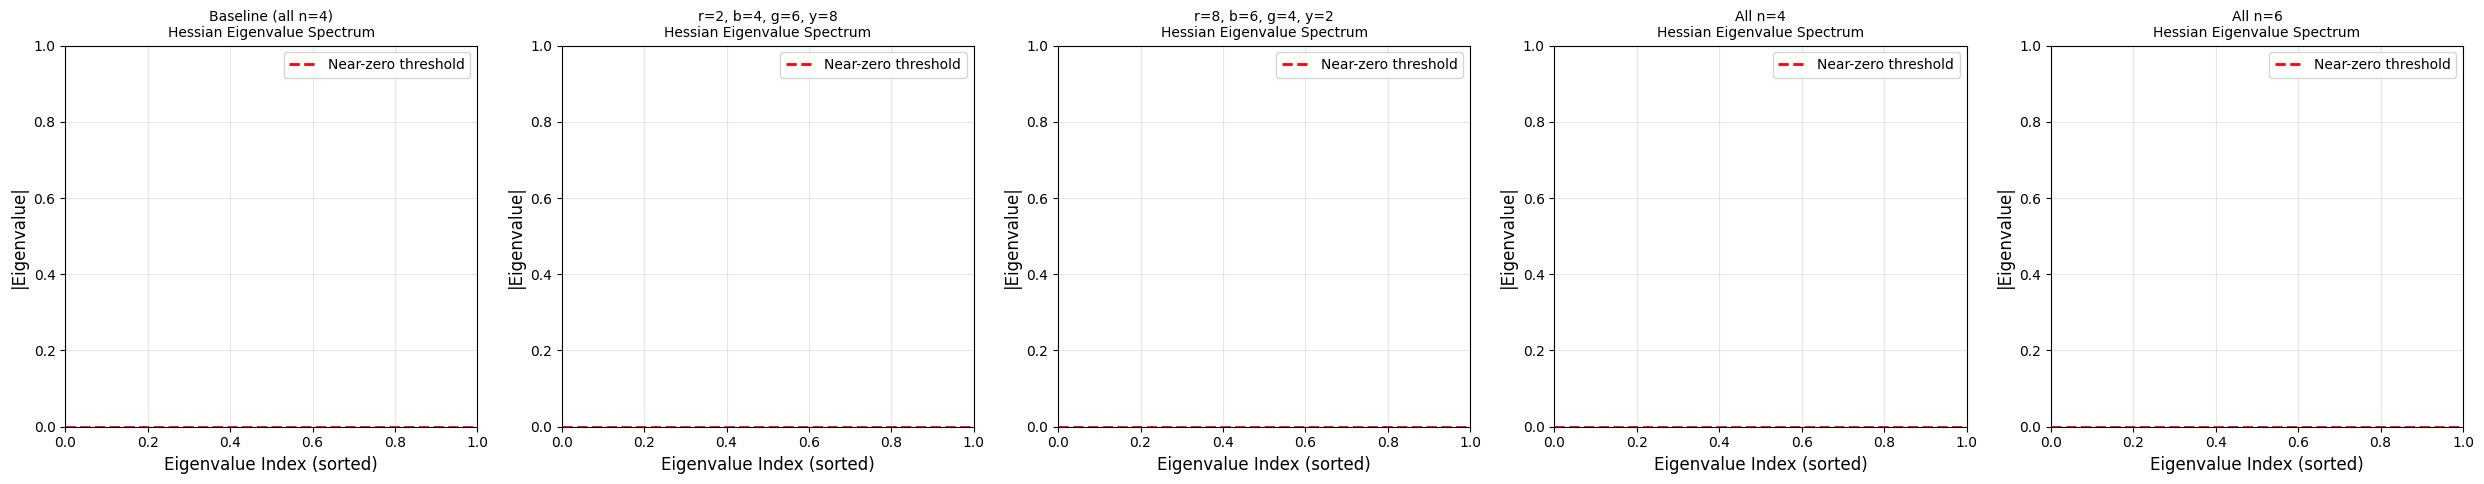

/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_52279/1608015790.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(ppr_data, labels=names, patch_artist=True, showmeans=True)
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


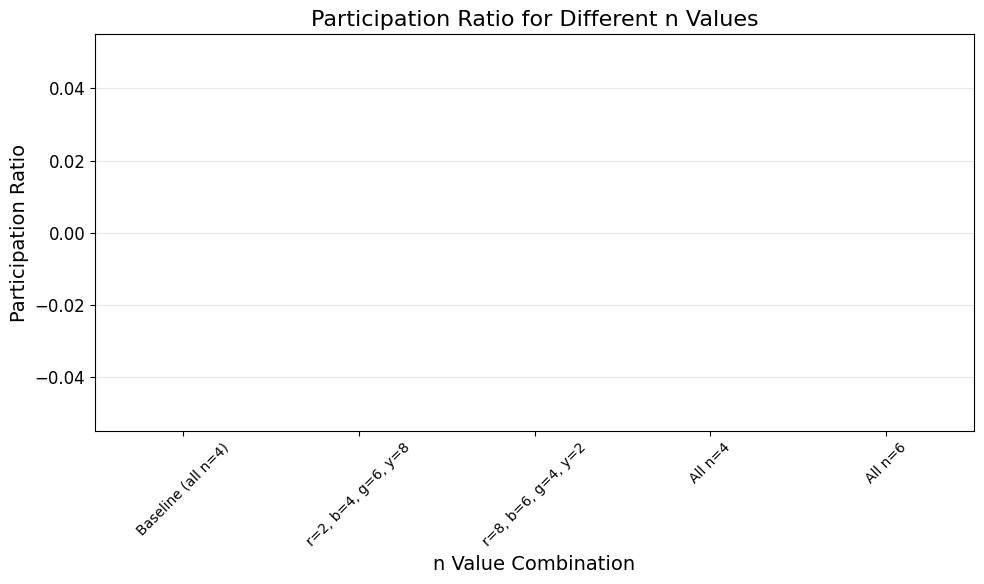


HESSIAN ANALYSIS SUMMARY
Combination                              Mean PPR        Mean Near-Zero 
--------------------------------------------------------------------------------
Baseline (all n=4)                                nan          nan
r=2, b=4, g=6, y=8                                nan          nan
r=8, b=6, g=4, y=2                                nan          nan
All n=4                                           nan          nan
All n=6                                           nan          nan


/Users/hizakim/4th_yr_project/.venv/lib/python3.9/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/hizakim/4th_yr_project/.venv/lib/python3.9/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [21]:
# Plot Hessian eigenvalue spectra
if len(hessian_results_all) > 0:
    fig, axes = plt.subplots(1, len(hessian_results_all), figsize=(5*len(hessian_results_all), 5))
    
    if len(hessian_results_all) == 1:
        axes = [axes]
    
    for idx, (name, data) in enumerate(hessian_results_all.items()):
        ax = axes[idx]
        
        # Plot all eigenvalue spectra
        for eigenvals in data['all_eigenvalues']:
            sorted_eigenvals = np.sort(np.abs(eigenvals))[::-1]
            ax.semilogy(sorted_eigenvals, 'o-', ms=3, alpha=0.5, linewidth=1)
        
        ax.axhline(1e-6, color='r', ls='--', lw=2, label='Near-zero threshold')
        ax.set_xlabel('Eigenvalue Index (sorted)', fontsize=12)
        ax.set_ylabel('|Eigenvalue|', fontsize=12)
        ax.set_title(f"{name}\nHessian Eigenvalue Spectrum", fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=10)
        ax.tick_params(labelsize=10) 
    
    plt.tight_layout()
    plt.savefig('Figures/hessian_spectrum_different_n.eps', format='eps', dpi=300)
    plt.show()
    
    # Compare participation ratios
    fig, ax = plt.subplots(figsize=(10, 6))
    
    names = list(hessian_results_all.keys())
    ppr_data = [hessian_results_all[name]['participation_ratios'] for name in names]
    
    bp = ax.boxplot(ppr_data, labels=names, patch_artist=True, showmeans=True)
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    
    ax.set_ylabel('Participation Ratio', fontsize=14)
    ax.set_xlabel('n Value Combination', fontsize=14)
    ax.set_title('Participation Ratio for Different n Values', fontsize=16)
    ax.tick_params(axis='x', rotation=45, labelsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig('Figures/participation_ratio_different_n.eps', format='eps', dpi=300)
    plt.show()
    
    # Print summary
    print("\n" + "="*80)
    print("HESSIAN ANALYSIS SUMMARY")
    print("="*80)
    print(f"{'Combination':<40} {'Mean PPR':<15} {'Mean Near-Zero':<15}")
    print("-"*80)
    for name, data in hessian_results_all.items():
        mean_ppr = np.mean(data['participation_ratios'])
        mean_nz = np.mean(data['near_zero_counts'])
        print(f"{name:<40} {mean_ppr:>12.2f} {mean_nz:>12.1f}")


## Effect of Individual n Values

Now we systematically vary each n value individually while keeping others fixed to see their individual effects.


In [ ]:
# Test individual n values: vary one at a time
n_values_individual = [2, 3, 4, 5, 6, 7, 8]
neuron_types = ['n_r', 'n_b', 'n_g', 'n_y']
neuron_names = ['Red (r)', 'Blue (b)', 'Green (g)', 'Mitral (y)']

individual_results = {}

# Use one sample for this analysis
theta_test = theta_subset[0, :]

for neuron_type, neuron_name in zip(neuron_types, neuron_names):
    print(f"\nVarying {neuron_name} ({neuron_type})...")
    
    max_real_parts = []
    min_real_parts = []
    stability_flags = []
    
    for n_val in n_values_individual:
        # Set all to 4, then change the one we're testing
        n_r, n_b, n_g, n_y = 4, 4, 4, 4
        if neuron_type == 'n_r':
            n_r = n_val
        elif neuron_type == 'n_b':
            n_b = n_val
        elif neuron_type == 'n_g':
            n_g = n_val
        elif neuron_type == 'n_y':
            n_y = n_val
        
        try:
            # Get fixed point
            r_star, g_star, b_star, y_star = mitral_output(theta_test, x, m, n_r, n_b, n_g, n_y)
            s_star = jnp.concatenate([r_star, g_star, y_star])
            
            # Compute stability
            result = compute_stability(F, s_star, theta_test, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
            
            max_real_parts.append(np.max(result['real_parts']))
            min_real_parts.append(np.min(result['real_parts']))
            stability_flags.append(result['is_stable'])
            
        except Exception as e:
            print(f"  n={n_val}: Error - {e}")
            max_real_parts.append(np.nan)
            min_real_parts.append(np.nan)
            stability_flags.append(False)
    
    individual_results[neuron_type] = {
        'n_values': n_values_individual,
        'max_real_parts': np.array(max_real_parts),
        'min_real_parts': np.array(min_real_parts),
        'stability_flags': np.array(stability_flags),
        'name': neuron_name
    }
    
    print(f"  Stable for n values: {[n for n, stable in zip(n_values_individual, stability_flags) if stable]}")


NameError: name 'individual_results' is not defined

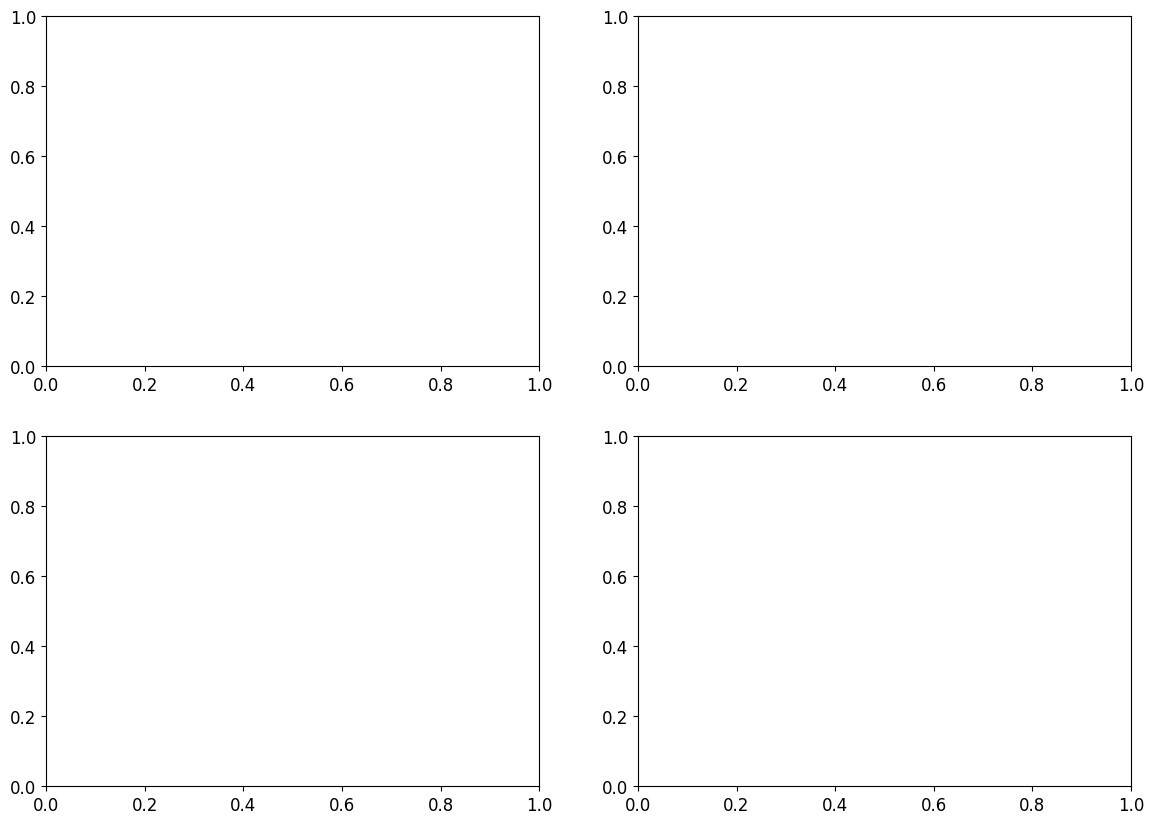

In [22]:
# Plot individual n value effects
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (neuron_type, data) in enumerate(individual_results.items()):
    ax = axes[idx]
    
    n_vals = data['n_values']
    max_real = data['max_real_parts']
    min_real = data['min_real_parts']
    stable = data['stability_flags']
    
    # Plot max and min real parts
    ax.plot(n_vals, max_real, 'o-', label='Max real part', linewidth=2, markersize=6)
    ax.plot(n_vals, min_real, 's-', label='Min real part', linewidth=2, markersize=6)
    
    # Highlight stable/unstable
    for i, (n, is_stable) in enumerate(zip(n_vals, stable)):
        if is_stable:
            ax.axvline(n, color='green', alpha=0.2, linewidth=3)
        else:
            ax.axvline(n, color='red', alpha=0.2, linewidth=3)
    
    ax.axhline(0, color='black', linestyle='--', linewidth=2, label='Stability threshold')
    ax.set_xlabel('n value', fontsize=12)
    ax.set_ylabel('Real Part of Eigenvalues', fontsize=12)
    ax.set_title(f"Effect of {data['name']} n value on Stability", fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=10)
    ax.tick_params(labelsize=10)

plt.tight_layout()
plt.savefig('Figures/individual_n_effects.eps', format='eps', dpi=300)
plt.show()


## Summary and Conclusions

This analysis shows how different Hill coefficients (n values) for each neuron type affect:
1. **Stability**: Higher n values generally lead to different stability characteristics
2. **Eigenvalue spectra**: The distribution of eigenvalues changes with n
3. **Hessian properties**: Participation ratio and near-zero eigenvalues vary with n

Key observations:
- Different n values can significantly affect network stability
- The effect depends on which neuron type's n is changed
- Some combinations may be more stable than others
